In [1]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict


plt.style.use('seaborn')

In [2]:
input_folder = "../build/CPlexCutsPower_20.05.2023_Сб_22-28"

In [48]:
col_cplex_time_after_cuts = "Time cplex after adding cuts"
col_duality_gap_decrease = "Duality gap decrease (ILP)"
col_time_generating_cuts = "Time generating cuts"
col_ilp_value_with_cuts = "ILP solution value with cuts"
col_cplex_time_baseline = "Time cplex baseline"
col_ilp_value_baseline = "ILP solution value baseline"
col_time_cuts_plus_cplex = "Time cuts + cplex"

In [3]:
def search_patterns(filename_pattern, name_pattern, pattern_list, source_dict):
    """
    Iterates all filenames which names satisfy filename_pattern. Retrieves problem name from 
    filename and search for every pattern in pattern_list. Then adds found values to source_dict
    Arguments:
        filename_pattern: regex pattern to select filenames
        name_pattern: regex pattern to retrieve problem name
        pattern_list: list consisting of tuples (pattern, group_name, column_name).
            all patterns contains named group, group_name used to retrieve result from groupdict object
            column_name used to add result to source_dict
        source_dict: dict to add found values
    """
    for filename in glob.glob(filename_pattern):
        match = re.search(name_pattern, filename)
        problem_name = match[0]
        with open(filename, "r") as file:
            file_content = file.read()
            if "terminate..." not in file_content:
                for pattern, group_name, column_name in pattern_list:
                    match = re.search(pattern, file_content)
                    if match:
                        found = match.groupdict()[group_name]
                        source_dict[problem_name][column_name] = found


def parse_logs(logs_dir: str):
    """ 
    Parse logs from logs_dir, return df with parse results. For results with cuts it retrieves
    total time, time for generating cuts, duality gap decrease, ILP solution value. For baseline
    results it parse total time and ILP solution value
    """
    source_dict = defaultdict(dict)

    # Parse results with cuts
    # note: regex used for number with exponent: [-+]*\d*\.*\d+([eE][-+]?\d+)?
    pattern_total_time = r"Total \(root\+branch&cut\) =\s*(?P<total_time>\d+\.\d+)"
    pattern_duality_gap = r"Duality gap decrease \(ILP\): (?P<gap>[-+]*\d*\.*\d+([eE][-+]?\d+)?)"
    pattern_time_cuts = r"total time: (?P<time_cuts>\d+\.\d+)"
    pattern_ilp_value_cuts = r"\nILP solution value:\s*(?P<ilp_solution_value>[-+]*\d*\.*\d+([eE][-+]?\d+)?)"

    pattern_list_cuts = (
        (pattern_total_time, "total_time", col_cplex_time_after_cuts),
        (pattern_duality_gap, "gap", col_duality_gap_decrease),
        (pattern_time_cuts, "time_cuts", col_time_generating_cuts),
        (pattern_ilp_value_cuts, "ilp_solution_value", col_ilp_value_with_cuts)
    )
    search_patterns(
        filename_pattern = f"{logs_dir}/*gz_log.txt",
        name_pattern = r"(?<=/)[^/]+(?=.mps.gz_log.txt)",
        pattern_list = pattern_list_cuts,
        source_dict = source_dict
    )

    # Parse baseline results (cplex)
    pattern_time_cplex_baseline = r"Total \(root\+branch&cut\) =\s*(?P<total_baseline_time>\d+\.\d+)"
    pattern_ilp_value_baseline = r"\nILP solution value:\s*(?P<ilp_solution_value>[-+]*\d*\.*\d+([eE][-+]?\d+)?)"
    
    pattern_list_baseline = (
        (pattern_time_cplex_baseline, "total_baseline_time", col_cplex_time_baseline),
        (pattern_ilp_value_baseline, "ilp_solution_value", col_ilp_value_baseline)
    )

    
    search_patterns(
        filename_pattern = f"{logs_dir}/*gz_b_log.txt",
        name_pattern = r"(?<=/)[^/]+(?=.mps.gz_b_log.txt)",
        pattern_list = pattern_list_baseline,
        source_dict = source_dict
    )

    # Construct dataframe
    result_df = pd.DataFrame(source_dict).transpose()

    result_df[col_cplex_time_after_cuts] = result_df[col_cplex_time_after_cuts].astype(float)
    result_df[col_duality_gap_decrease] = result_df[col_duality_gap_decrease].astype(float)
    result_df[col_time_generating_cuts] = result_df[col_time_generating_cuts].astype(float)
    result_df[col_ilp_value_with_cuts] = result_df[col_ilp_value_with_cuts].fillna(0).astype(float).astype(int).replace(0, np.nan)

    result_df[col_cplex_time_baseline] = result_df[col_cplex_time_baseline].astype(float)
    result_df[col_ilp_value_baseline] = result_df[col_ilp_value_baseline].fillna(0).astype(float).astype(int).replace(0, np.nan)

    # Add total time with cuts
    result_df[col_time_cuts_plus_cplex] = result_df[col_cplex_time_after_cuts] + result_df[col_time_generating_cuts]

    # Order columns
    columns_order = [col_time_generating_cuts, col_cplex_time_after_cuts, col_time_cuts_plus_cplex,
                     col_duality_gap_decrease, col_ilp_value_with_cuts,
                     col_cplex_time_baseline, col_ilp_value_baseline]
    result_df = result_df[columns_order]
    return result_df

result_df = parse_logs(input_folder)
result_df

,Time generating cuts,Time cplex after adding cuts,Time cuts + cplex,Duality gap decrease (ILP),ILP solution value with cuts,Time cplex baseline,ILP solution value baseline
reblock115,67.364600,8182.44,8249.804600,2.573150e-03,-36800600.0,4105.16,-36800600.0
glass-sc,0.683623,3119.84,3120.523623,2.387690e-03,23.0,2727.64,23.0
neos859080,0.407212,36.86,37.267212,NaN,NaN,56.74,NaN
pb-market-split8-70-4,0.087287,NaN,NaN,NaN,NaN,NaN,NaN
cod105_vc1024,178.600000,25.18,203.780000,-7.347660e-15,-12.0,26.92,-12.0
seymour,60.886000,12559.28,12620.166000,2.109330e-02,423.0,NaN,NaN
enlight_hard,0.547682,0.01,0.557682,4.864860e-01,37.0,0.02,37.0


In [4]:
def show_transposed(result_df):
    return result_df.astype(str).replace('nan',np.nan).transpose()

show_transposed(result_df)

,reblock115,glass-sc,neos859080,pb-market-split8-70-4,cod105_vc1024,seymour,enlight_hard
Time generating cuts,67.3646,0.683623,0.407212,0.0872868,178.6,60.886,0.547682
Time cplex after adding cuts,8182.44,3119.84,36.86,NaN,25.18,12559.28,0.01
Time cuts + cplex,8249.8046,3120.523623,37.267212,NaN,203.78,12620.166000000001,0.557682
Duality gap decrease (ILP),0.00257315,0.00238769,NaN,NaN,-7.34766e-15,0.0210933,0.486486
ILP solution value with cuts,-36800600.0,23.0,NaN,NaN,-12.0,423.0,37.0
Time cplex baseline,4105.16,2727.64,56.74,NaN,26.92,NaN,0.02
ILP solution value baseline,-36800600.0,23.0,NaN,NaN,-12.0,NaN,37.0


In [ ]:
# from math import ceil
# import seaborn as sns
# import matplotlib.pyplot as plt


# def plot_bar(df, colsize=4, hide_empty_subplots=True):
#     x_axis = np.arange(len(df))
#     fig, axs = plt.subplots(ceil(len(df) / colsize), colsize, figsize=(14, 8), squeeze=False)
#     for row, row_axs in enumerate(axs):
#         for col, ax in enumerate(row_axs):
#             ax.set_xticks([])
#             ax.set_ylabel("Sec.")

#             index = row * colsize + col
#             if index >= len(df):
#                 if hide_empty_subplots:
#                     ax.axis('off')
#                 continue
            

#             ilpcuts_time = df.iloc[[index]]["Time cplex after adding cuts"]
#             baseline_time = df.iloc[[index]]["Time cplex baseline"]

#             if not ilpcuts_time.isnull().any():
#                 ax.bar(-0.2, ilpcuts_time, width=0.4)
#             else:
#                 baseline_bar = ax.bar(-0.2, [0], width=0.4)
            
#             if not baseline_time.isnull().any():
#                 ax.bar(0.2, baseline_time, width=0.4)
#             else:
#                 ax.bar(0.2, [0], width=0.4)
#             ax.set_xlabel(df.iloc[[index]].index.values[0])
#     labels = ["CPLEX time after adding cuts", "CPLEX baseline time"]
#     fig.legend(
#         labels=labels,
#         loc="lower center",
#         bbox_to_anchor=(0.5, -0.01),
#         fancybox=True,
#         shadow=True,
#         ncol=len(labels)
#     )
#     plt.subplots_adjust(right=0.7)
#     plt.tight_layout()
#     plt.show()

# filtered_df = result_df  # .loc[["reblock115", "glass-sc", "seymour"]]
# plot_bar(filtered_df)

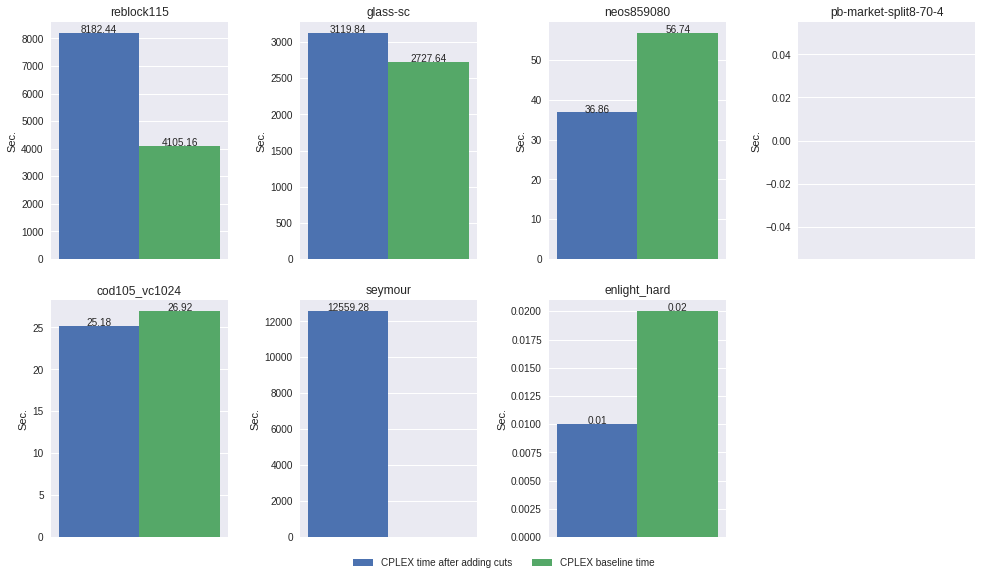

In [44]:
from math import ceil
import seaborn as sns
import matplotlib.pyplot as plt


def plot_bar(df, colsize=4, hide_empty_subplots=True):
    x_axis = np.arange(len(df))
    fig, axs = plt.subplots(ceil(len(df) / colsize), colsize, figsize=(14, 8), squeeze=False)
    for row, row_axs in enumerate(axs):
        for col, ax in enumerate(row_axs):
            ax.set_xticks([])
            ax.set_ylabel("Sec.")

            index = row * colsize + col
            if index >= len(df):
                if hide_empty_subplots:
                    ax.axis('off')
                continue
            

            ilpcuts_time = df.iloc[[index]]["Time cplex after adding cuts"]
            baseline_time = df.iloc[[index]]["Time cplex baseline"]
            # time_values = [str(ilpcuts_time.iloc[0]), str(baseline_time.iloc[0])]
            time_values = [ilpcuts_time.iloc[0], baseline_time.iloc[0]]
            x1_coordinate = -0.2
            x2_coordinate = 0.2
            if not ilpcuts_time.isnull().any():
                ax.bar(x1_coordinate, ilpcuts_time, width=0.4)
                ax.text(x1_coordinate, time_values[0], time_values[0], ha = 'center')
            else:
                ax.bar(x1_coordinate, [0], width=0.4)
            
            if not baseline_time.isnull().any():
                ax.bar(x2_coordinate, baseline_time, width=0.4)
                ax.text(x2_coordinate, time_values[1], time_values[1], ha = 'center')
            else:
                ax.bar(x2_coordinate, [0], width=0.4)
            
            # ax.set_xticks([x1_coordinate, x2_coordinate])
            # ax.set_xticklabels(time_values)
            
            
            ax.set_title(df.iloc[[index]].index.values[0])
    labels = ["CPLEX time after adding cuts", "CPLEX baseline time"]
    fig.legend(
        labels=labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.01),
        fancybox=True,
        shadow=True,
        ncol=len(labels)
    )
    plt.subplots_adjust(right=0.7)
    plt.tight_layout(pad=2, h_pad=2)
    plt.show()

filtered_df = result_df  # .loc[["reblock115", "glass-sc", "seymour"]]
plot_bar(filtered_df)

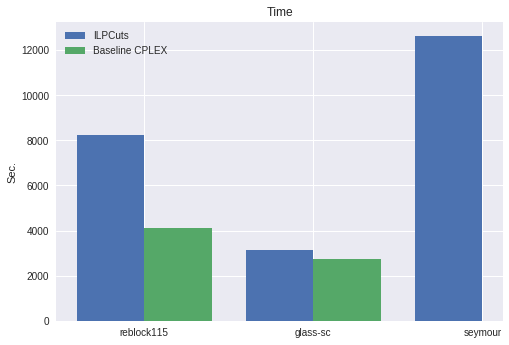

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt


# plt.bar(result_df.index.values, result_df["Time cuts + cplex"])

def plot_bar(df):
    x_axis = np.arange(len(df))
    plt.bar(x_axis -0.2, df["Time cuts + cplex"], width=0.4, label = 'ILPCuts')
    plt.bar(x_axis +0.2, df["Time cplex baseline"], width=0.4, label = 'Baseline CPLEX')
    plt.title("Time")
    plt.xticks(x_axis, df.index.values)
    plt.ylabel("Sec.")
    plt.legend()
    plt.show()

filtered_df = result_df.loc[["reblock115", "glass-sc", "seymour"]]
plot_bar(filtered_df)

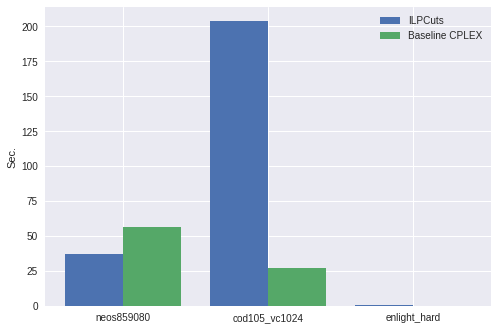

In [30]:
filtered_df = result_df.loc[["neos859080", "cod105_vc1024", "enlight_hard"]]
plot_bar(filtered_df)

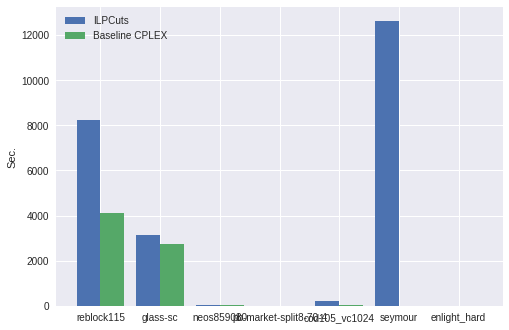

In [29]:
plot_bar(result_df)

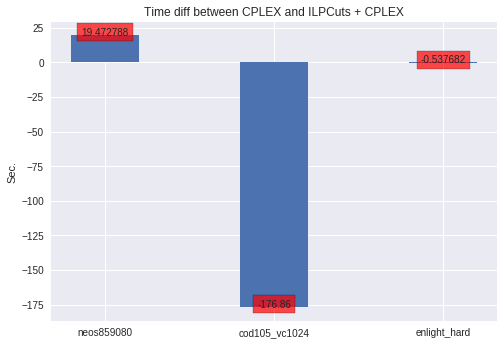

In [45]:
def plot_single_bar(df):
    x_axis = np.arange(len(df))
    plt.bar(x_axis, df["Time diff"], width=0.4)
    plt.title("Time diff between CPLEX and ILPCuts + CPLEX")
    plt.xticks(x_axis, df.index.values)
    for i in range(len(df["Time diff"])):
        plt.text(i, df["Time diff"][i], df["Time diff"][i], ha = 'center', Bbox = dict(facecolor = 'red', alpha =.7))
    plt.ylabel("Sec.")
    plt.show()

filtered_df = result_df.loc[["neos859080", "cod105_vc1024", "enlight_hard"]]
filtered_df["Time diff"] = filtered_df["Time cplex baseline"] - filtered_df["Time cuts + cplex"]
plot_single_bar(filtered_df)

In [138]:
def plot_single_bar(df):
    x_axis = np.arange(len(df))
    plt.figure(figsize=(14, 8))
    diff_column = df["Time diff"]
    plt.bar(x_axis, diff_column, width=0.4)
    plt.title("Time diff between CPLEX and ILPCuts + CPLEX")
    plt.xticks(x_axis, df.index.values)
    for i in range(len(diff_column)):
        diff = round(diff_column[i] if diff_column[i] != np.nan else 0.0, 5)
        plt.text(i, diff, diff, ha = 'center', Bbox = dict(facecolor = 'red', alpha =.7))
    plt.ylabel("Sec.")
    plt.show()

#### Time difference between cut generation + CPLEX and baseline CPLEX

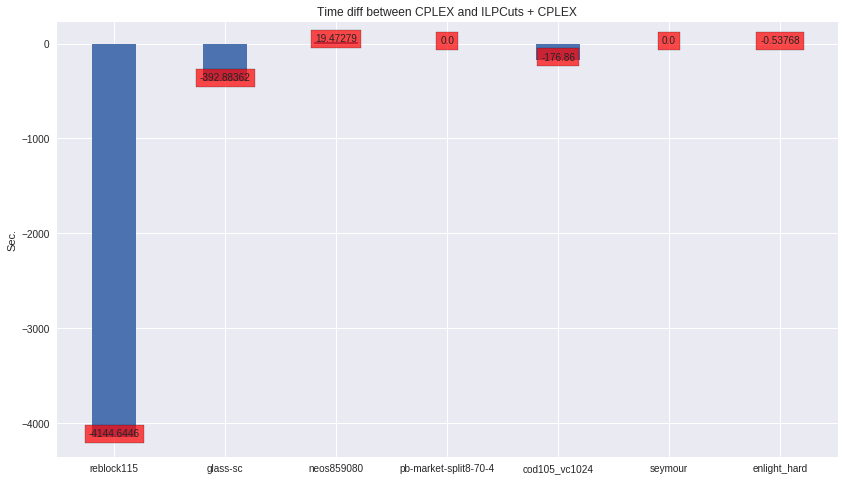

In [139]:
filtered_df = result_df  # .loc[["neos859080", "cod105_vc1024", "enlight_hard"]]
filtered_df["Time diff"] = (filtered_df[col_cplex_time_baseline] - filtered_df[col_time_cuts_plus_cplex]).fillna(0.0)
plot_single_bar(filtered_df)

#### Time difference between CPLEX after adding cuts and baseline CPLEX

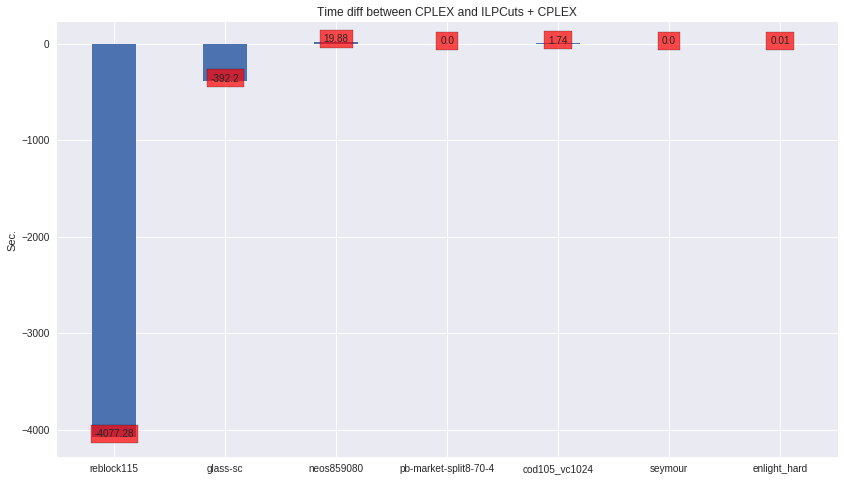

In [140]:
filtered_df = result_df
filtered_df["Time diff"] = (filtered_df[col_cplex_time_baseline] - filtered_df[col_cplex_time_after_cuts]).fillna(0.0)
plot_single_bar(filtered_df)

#### Time difference between CPLEX after adding cuts and baseline CPLEX. Best problems

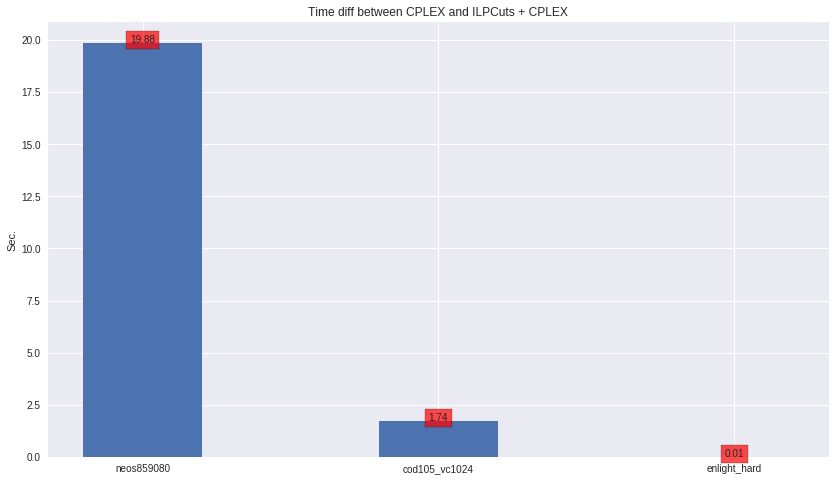

In [141]:
filtered_df = result_df.loc[["neos859080", "cod105_vc1024", "enlight_hard"]]
filtered_df["Time diff"] = (filtered_df[col_cplex_time_baseline] - filtered_df[col_cplex_time_after_cuts]).fillna(0.0)
plot_single_bar(filtered_df)